# 3주차 실습 — Hugging Face & Colab 온보딩 (변형: 흉부 X-ray 폐렴 분류)
### 비전AI와비즈니스 | 경영대학 AI빅데이터융합경영학과

**원본 대비 변경 사항**
| 항목 | 원본 | 변경 |
|---|---|---|
| 데이터셋 | `AI-Lab-Makerere/beans` (콩잎 병해 3종) | `hf-vision/chest-xray-pneumonia` (소아 흉부 X-ray, NORMAL / PNEUMONIA) |
| 모델 | `google/vit-base-patch16-224` (ViT) | `facebook/convnext-tiny-224` (ConvNeXt, CNN 계열) |
| 평가 | Accuracy | Accuracy + F1 + 민감도/특이도 + Confusion Matrix |
| 추가 | — | 학습 전 성능 측정, Grad-CAM(XAI) 시각화 |


---
## ⚙️ 설정 — 여기만 바꾸면 다른 데이터/모델로도 그대로 동작


In [1]:
# 실습 전체에서 사용할 데이터셋과 모델 (여기만 바꾸면 됨)
DATASET    = "hf-vision/chest-xray-pneumonia"   # 소아 흉부 X-ray (CC BY 4.0)
CHECKPOINT = "facebook/convnext-tiny-224"       # ImageNet-1k 사전학습 ConvNeXt-Tiny (Apache-2.0)
SEED = 42


---
## 0. 시작 전 — Colab 런타임 설정

상단 메뉴에서 **런타임(Runtime) → 런타임 유형 변경(Change runtime type)** 을 클릭하고,
하드웨어 가속기를 **T4 GPU** 로 설정하세요.

아래 셀을 실행해 GPU가 정상적으로 할당되었는지 확인합니다.


In [2]:
# GPU 확인 — 표가 출력되면 GPU 정상 할당
!nvidia-smi

Wed Oct  7 15:28:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import torch
print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())
print("GPU 이름:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU만 사용 중")

PyTorch 버전: 2.11.0+cu130
GPU 사용 가능: True
GPU 이름: Tesla T4


---
## 1. 라이브러리 설치

Hugging Face의 핵심 라이브러리를 설치합니다.

- `transformers` : 사전학습 모델을 불러오고 추론하는 핵심 라이브러리
- `datasets` : Hugging Face Hub의 공개 데이터셋을 불러오는 라이브러리
- `pillow` : 이미지 처리

> 💡 Colab에는 이미 대부분 설치되어 있어 몇 초면 끝납니다.


In [4]:
!pip install -q transformers datasets pillow
print("설치 완료 ✅")

설치 완료 ✅


---
## 2. Hugging Face 둘러보기 (웹)

1. https://huggingface.co/models 접속 → **Tasks: Image Classification** 필터
2. **`facebook/convnext-tiny-224`** 검색 → 모델 카드에서 입력 크기·라이선스·사용 예제 확인 (📸 보고서 그림 1)
3. https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia 에서 데이터셋 카드(출처·라이선스·split 크기) 확인


---
## 3. 첫 번째 추론 — `pipeline`


In [5]:
from transformers import pipeline

classifier = pipeline(task="image-classification", model=CHECKPOINT)
print("모델 로딩 완료:", CHECKPOINT)


pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: downloading bytes:           |  0.00B            

모델 로딩 완료: facebook/convnext-tiny-224


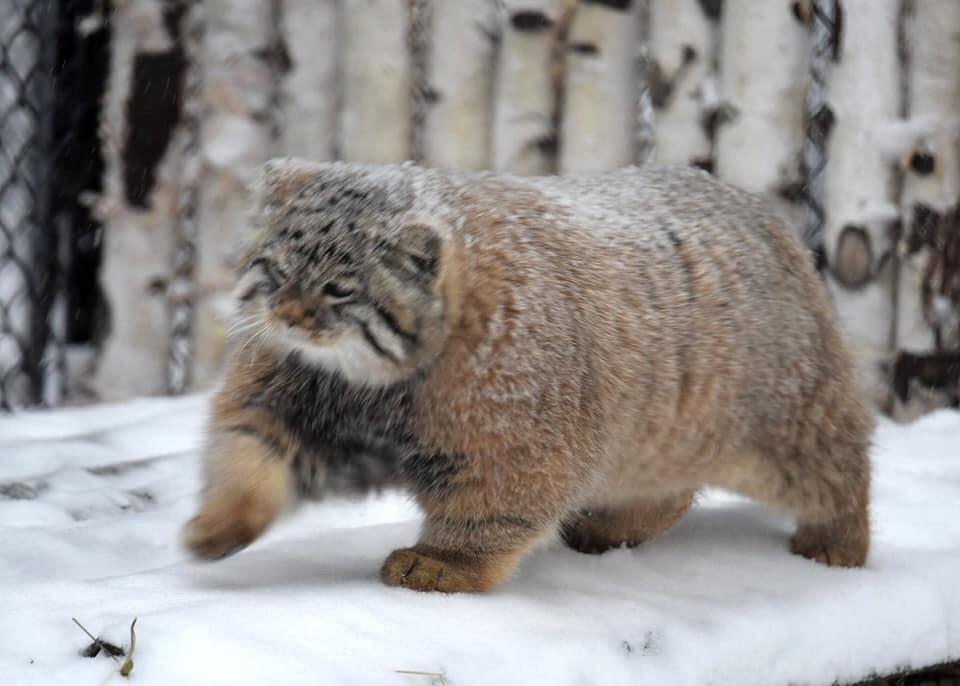

In [6]:
from PIL import Image
import requests

# 예제 이미지 불러오기 (고양이 사진)
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
image = Image.open(requests.get(url, stream=True).raw)
image  # 셀 마지막 줄에 변수를 두면 이미지가 표시됩니다

In [7]:
# 추론 실행
results = classifier(image)

# 상위 5개 예측 결과 출력
for r in results:
    print(f"{r['label']:30s}  {r['score']:.3f}")

lynx, catamount                 0.736
wombat                          0.059
badger                          0.025
marmot                          0.015
tabby, tabby cat                0.009


**결과 해석**
- `label` : 예측 클래스(ImageNet 1000개 중 하나), `score` : 확신도
- ConvNeXt는 ViT의 설계 아이디어를 CNN에 적용한 모델입니다. 구조가 달라도 `pipeline` 사용법은 동일합니다.


---
## 4. 내 이미지로 바꿔보기

이제 예제 이미지 대신 **여러분이 직접 올린 이미지**로 추론해 봅니다.

### 실습
1. 왼쪽 사이드바의 **폴더 아이콘(📁)** 클릭
2. 이미지 파일을 드래그해서 업로드 (또는 아래 셀로 업로드)
3. 파일명을 `my_image.jpg` 로 맞추거나, 코드의 경로를 바꿔주세요


In [ ]:
from google.colab import files
uploaded = files.upload()  # 파일 선택창이 열립니다

In [ ]:
# 업로드한 파일명으로 변경하세요
fname = list(uploaded.keys())[0] if uploaded else "my_image.jpg"

my_image = Image.open(fname)
display(my_image.resize((300, 300)))

for r in classifier(my_image):
    print(f"{r['label']:30s}  {r['score']:.3f}")

---
## 5. 공개 데이터셋 불러오기 — 흉부 X-ray

> 정렬된 데이터일 수 있으므로 `shuffle` 후 일부만 뽑아 봅니다.


In [8]:
from datasets import load_dataset, ClassLabel, Image as HFImage

ds = load_dataset(DATASET, split="test").shuffle(seed=SEED).select(range(20))

# 컬럼 이름을 자동으로 찾기 (데이터셋마다 'label' / 'labels' 등 이름이 다름)
LABEL_COL = [k for k, v in ds.features.items() if isinstance(v, ClassLabel)][0]
IMAGE_COL = [k for k, v in ds.features.items() if isinstance(v, HFImage)][0]
print(ds)
print("이미지 컬럼:", IMAGE_COL, "| 라벨 컬럼:", LABEL_COL)
print("클래스:", ds.features[LABEL_COL].names)


data/train-00000-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00003-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00004-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00005-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00006-of-00007.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Dataset({
    features: ['image', 'label'],
    num_rows: 20
})
이미지 컬럼: image | 라벨 컬럼: label
클래스: ['NORMAL', 'PNEUMONIA']


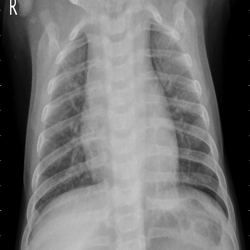

정답 라벨: PNEUMONIA


In [9]:
sample = ds[0]
display(sample[IMAGE_COL].resize((250, 250)))
print("정답 라벨:", ds.features[LABEL_COL].names[sample[LABEL_COL]])


### 실습 — 모델 예측 vs 실제 라벨
> ImageNet에는 '폐렴'이라는 클래스가 없으므로 X-ray를 엉뚱한 사물로 예측합니다. → 6번 전이학습의 출발점


In [10]:
names = ds.features[LABEL_COL].names
for i in range(5):
    img = ds[i][IMAGE_COL].convert("RGB")   # X-ray는 흑백(1채널) → RGB 3채널로 변환
    pred = classifier(img)[0]
    print(f"[{i}] 실제: {names[ds[i][LABEL_COL]]:10s} | 예측: {pred['label'][:30]:30s} ({pred['score']:.2f})")


[0] 실제: PNEUMONIA  | 예측: shower curtain                 (0.22)
[1] 실제: NORMAL     | 예측: trilobite                      (0.83)
[2] 실제: NORMAL     | 예측: coil, spiral, volute, whorl, h (0.09)
[3] 실제: NORMAL     | 예측: trilobite                      (0.55)
[4] 실제: PNEUMONIA  | 예측: shower curtain                 (0.59)


---
## 6-1. 전이학습(Transfer Learning)의 개념

5번에서 봤듯, ImageNet으로 학습된 모델은 **새로운 도메인(흉부 X-ray 폐렴)** 을 잘 못 맞춥니다.
**전이학습**은 이미 학습된 모델의 지식을 가져와,
우리 데이터에 맞게 **일부만 다시 학습**시키는 방법입니다.

```
사전학습 모델 (일반 이미지 수백만 장으로 학습)
        │
        │  ← 특징 추출기(feature extractor)는 그대로 재사용
        ▼
  마지막 분류층만 교체 → 우리 데이터로 재학습
        │
        ▼
   우리 task 전용 모델 완성
```

전체를 처음부터 학습하는 것보다 **훨씬 적은 데이터·시간** 으로 좋은 성능을 냅니다.
프로젝트에서 여러분이 실제로 하게 될 작업이 바로 이것입니다.

> 아래는 전이학습의 **구조만** 보여주는 코드입니다.
> (실제 학습은 시간이 걸리므로 오늘은 '어떻게 생겼는지'만 확인합니다.)


---
## 6-2. 전이학습 실습 — `Trainer`로 파인튜닝하기


In [11]:
# 학습에 필요한 라이브러리 추가 설치
!pip install -q transformers datasets evaluate accelerate
print("설치 완료")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.6 MB/s eta 0:00:00
설치 완료


### ① 데이터셋 분할과 전처리

> ⚠️ 이 데이터셋의 공식 validation은 **16장뿐**이라 검증 곡선이 불안정합니다.
> 그래서 train의 10%를 **클래스 비율을 유지(stratify)** 하며 떼어내 검증셋으로 씁니다.


In [12]:
from datasets import load_dataset
from transformers import AutoImageProcessor
from collections import Counter
import torch

raw = load_dataset(DATASET)
labels = raw["train"].features[LABEL_COL].names
print("클래스:", labels)

split = raw["train"].train_test_split(test_size=0.1, stratify_by_column=LABEL_COL, seed=SEED)
raw_train, raw_val, raw_test = split["train"], split["test"], raw["test"]

for name, d in [("train", raw_train), ("val", raw_val), ("test", raw_test)]:
    cnt = Counter(d[LABEL_COL])
    print(f"{name:5s}: {len(d):5d}장 | " + ", ".join(f"{labels[k]}={v}" for k, v in sorted(cnt.items())))

processor = AutoImageProcessor.from_pretrained(CHECKPOINT)

def transform(batch):
    inputs = processor([img.convert("RGB") for img in batch[IMAGE_COL]], return_tensors="pt")
    inputs["labels"] = batch[LABEL_COL]
    return inputs

train_ds = raw_train.with_transform(transform)
val_ds   = raw_val.with_transform(transform)
test_ds  = raw_test.with_transform(transform)
print("데이터 준비 완료")


클래스: ['NORMAL', 'PNEUMONIA']
train:  4694장 | NORMAL=1207, PNEUMONIA=3487
val  :   522장 | NORMAL=134, PNEUMONIA=388
test :   624장 | NORMAL=234, PNEUMONIA=390
데이터 준비 완료


### ② collator와 평가지표

클래스 불균형(폐렴 비율이 높음)이 있어 **정확도만으로는 부족**합니다.
- **민감도(Sensitivity, Recall of PNEUMONIA)** : 실제 폐렴 중 놓치지 않은 비율 → 의료 선별검사에서 가장 중요
- **특이도(Specificity)** : 실제 정상 중 정상으로 맞힌 비율 → 낮으면 불필요한 추가 검사 증가
- **F1 (macro)** : 두 클래스를 동등하게 반영


In [13]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, recall_score

POS = next((i for i, n in enumerate(labels) if "pneu" in n.lower()), 1)   # 폐렴 클래스 index
NEG = 1 - POS

def collate_fn(batch):
    return {
        "pixel_values": torch.stack([x["pixel_values"] for x in batch]),
        "labels": torch.tensor([x["labels"] for x in batch]),
    }

def compute_metrics(eval_pred):
    preds = np.argmax(eval_pred.predictions, axis=1)
    y = eval_pred.label_ids
    return {
        "accuracy":    accuracy_score(y, preds),
        "f1_macro":    f1_score(y, preds, average="macro"),
        "sensitivity": recall_score(y, preds, pos_label=POS, average="binary", zero_division=0),
        "specificity": recall_score(y, preds, pos_label=NEG, average="binary", zero_division=0),
    }
print("collator·지표 준비 완료 | 양성 클래스:", labels[POS])


collator·지표 준비 완료 | 양성 클래스: PNEUMONIA


### ③ 사전학습 모델 불러오기 (분류층 1000 → 2 클래스 교체)


In [14]:
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained(
    CHECKPOINT,
    num_labels=len(labels),
    id2label={i: l for i, l in enumerate(labels)},
    label2id={l: i for i, l in enumerate(labels)},
    ignore_mismatched_sizes=True,
)
print("모델 준비 완료 (분류층 →", model.config.num_labels, "클래스)")
print(f"파라미터 수: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


[transformers] ConvNextForImageClassification LOAD REPORT from: facebook/convnext-tiny-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


모델 준비 완료 (분류층 → 2 클래스)
파라미터 수: 27.8M


### ④ 학습 설정 → **학습 전 성능 측정** → 학습 실행


In [15]:
from transformers import TrainingArguments, Trainer
import time

training_args = TrainingArguments(
    output_dir="./convnext-chestxray",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    learning_rate=5e-5,
    eval_strategy="epoch",            # 구버전이면 evaluation_strategy
    save_strategy="epoch",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro", # 불균형 데이터 → accuracy 대신 F1 기준
    save_total_limit=1,
    fp16=torch.cuda.is_available(),   # T4 GPU에서 속도 향상
    remove_unused_columns=False,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
)

# 학습 전(분류층 무작위 초기화 상태) 테스트 성능 → 보고서 표의 '학습 전' 값
before = trainer.evaluate(test_ds, metric_key_prefix="test")
print("[학습 전]", {k: round(v, 4) for k, v in before.items() if k.startswith("test_") and "runtime" not in k and "per_second" not in k})


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Sensitivity,Specificity
No log,0.735920,0,0.366987,0.295318,0.038462,0.914530


[학습 전] {'test_loss': 0.7359, 'test_accuracy': 0.367, 'test_f1_macro': 0.2953, 'test_sensitivity': 0.0385, 'test_specificity': 0.9145}


In [16]:
start = time.time()
trainer.train()
elapsed = time.time() - start
print(f"학습 소요 시간: {elapsed/60:.1f}분 / {training_args.num_train_epochs} epoch")


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Sensitivity,Specificity
1,0.097552,0.089860,0.975096,0.967606,0.979381,0.962687
2,0.031133,0.121682,0.967433,0.957639,0.974227,0.947761
3,0.013416,0.121966,0.973180,0.964687,0.984536,0.940299


학습 소요 시간: 5.8분 / 3 epoch


### ⑤ 최종 성능 확인 (테스트셋) & Confusion Matrix


In [17]:
after = trainer.evaluate(test_ds, metric_key_prefix="test")
keys = ["test_accuracy", "test_f1_macro", "test_sensitivity", "test_specificity"]
print(f"{'지표':18s} {'학습 전':>8s} {'학습 후':>8s}")
for k in keys:
    print(f"{k[5:]:18s} {before[k]:8.4f} {after[k]:8.4f}")


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Sensitivity,Specificity
0.013416,0.516724,3,0.850962,0.823799,0.994872,0.611111


지표                     학습 전     학습 후
accuracy             0.3670   0.8510
f1_macro             0.2953   0.8238
sensitivity          0.0385   0.9949
specificity          0.9145   0.6111


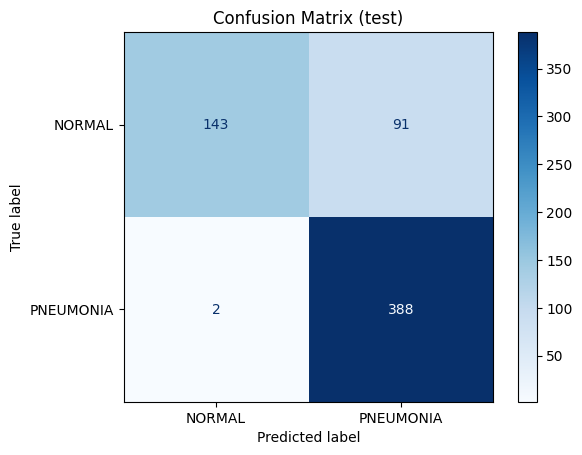

FN(폐렴을 정상으로 놓침): 2 | FP(정상을 폐렴으로 오진): 91


In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred_out = trainer.predict(test_ds)
y_pred = pred_out.predictions.argmax(axis=1)
y_true = pred_out.label_ids

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (test)")
plt.show()
print("FN(폐렴을 정상으로 놓침):", cm[POS, NEG], "| FP(정상을 폐렴으로 오진):", cm[NEG, POS])


### ⑥ 파인튜닝 모델로 추론 (보고서 그림 3)


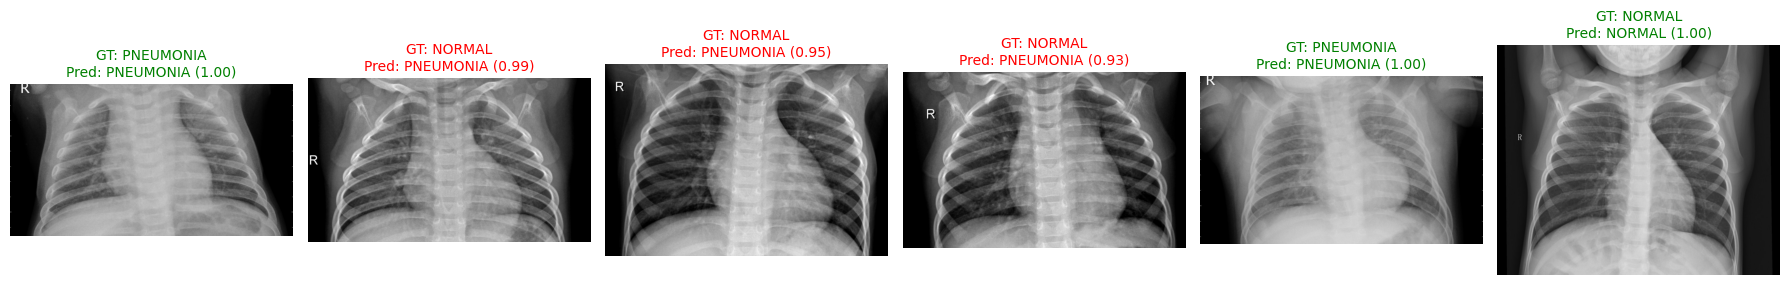

In [19]:
from transformers import pipeline

clf_finetuned = pipeline("image-classification", model=trainer.model, image_processor=processor,
                         device=0 if torch.cuda.is_available() else -1)

idx = raw_test.shuffle(seed=SEED).select(range(6))
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, ex in zip(axes, idx):
    img = ex[IMAGE_COL].convert("RGB")
    p = clf_finetuned(img)[0]
    true = labels[ex[LABEL_COL]]
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"GT: {true}\nPred: {p['label']} ({p['score']:.2f})",
                 color="green" if p["label"] == true else "red", fontsize=10)
plt.tight_layout(); plt.show()


### ⑦ 학습 곡선 (보고서 그림 4)


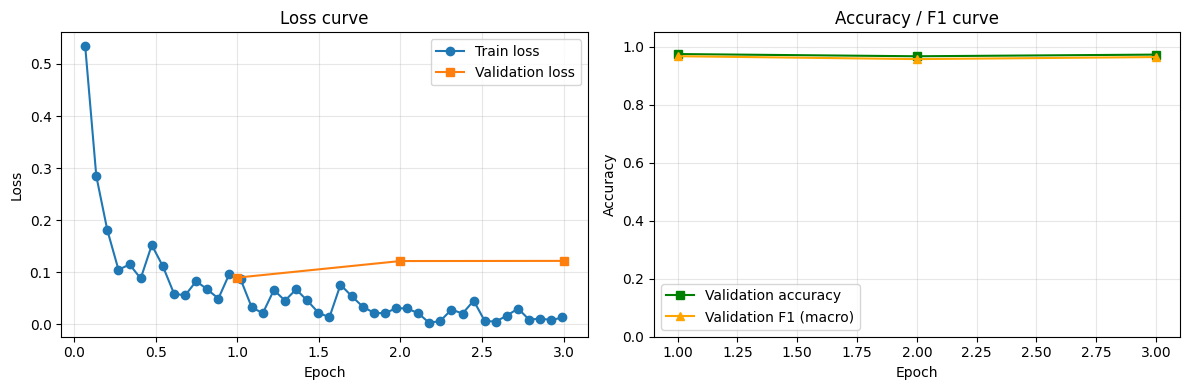

In [20]:
import matplotlib.pyplot as plt

# Trainer가 남긴 로그에서 필요한 값 추출
logs = trainer.state.log_history

train_steps, train_loss = [], []      # 학습 loss (logging_steps 마다 기록)
eval_epochs, eval_loss, eval_acc, eval_f1 = [], [], [], []   # 검증 지표 (epoch 마다 기록)

for rec in logs:
    if "loss" in rec and "epoch" in rec and "eval_loss" not in rec:
        train_steps.append(rec["epoch"])
        train_loss.append(rec["loss"])
    if "eval_loss" in rec:
        eval_epochs.append(rec["epoch"])
        eval_loss.append(rec["eval_loss"])
        eval_acc.append(rec["eval_accuracy"])
        eval_f1.append(rec["eval_f1_macro"])

# 그래프 2개: (왼쪽) loss, (오른쪽) 정확도
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 왼쪽 — Loss 곡선
ax1.plot(train_steps, train_loss, marker="o", label="Train loss")
ax1.plot(eval_epochs, eval_loss, marker="s", label="Validation loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Loss curve")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 오른쪽 — 정확도 곡선
ax2.plot(eval_epochs, eval_acc, marker="s", color="green", label="Validation accuracy")
ax2.plot(eval_epochs, eval_f1, marker="^", color="orange", label="Validation F1 (macro)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.set_title("Accuracy / F1 curve")
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**곡선 해석 팁**
- 학습 loss와 검증 loss가 **함께 내려가면** 정상적으로 학습되는 중입니다.
- 학습 loss는 계속 내려가는데 **검증 loss가 다시 올라가면** 과적합 신호 → epoch를 줄이거나 데이터 증강을 고려합니다.
- 검증 정확도가 **평평해지면(수렴)** 더 학습해도 큰 향상이 없다는 뜻입니다.

> 3 epoch는 곡선이 짧아 경향만 보입니다. `num_train_epochs`를 늘리면 더 뚜렷하게 관찰할 수 있습니다.


---
## 6-3. (추가) XAI — Grad-CAM으로 모델이 '어디를 보고' 판단했는지 확인

정확도가 높아도 모델이 **폐 실질이 아닌 곳**(글자 마커, 가장자리, 기구 등)을 보고 맞혔다면 실제 임상에서는 신뢰할 수 없습니다.
Grad-CAM은 마지막 합성곱 단계의 특징맵에 예측 클래스의 기울기를 가중해 **판단 근거 영역**을 히트맵으로 보여줍니다.


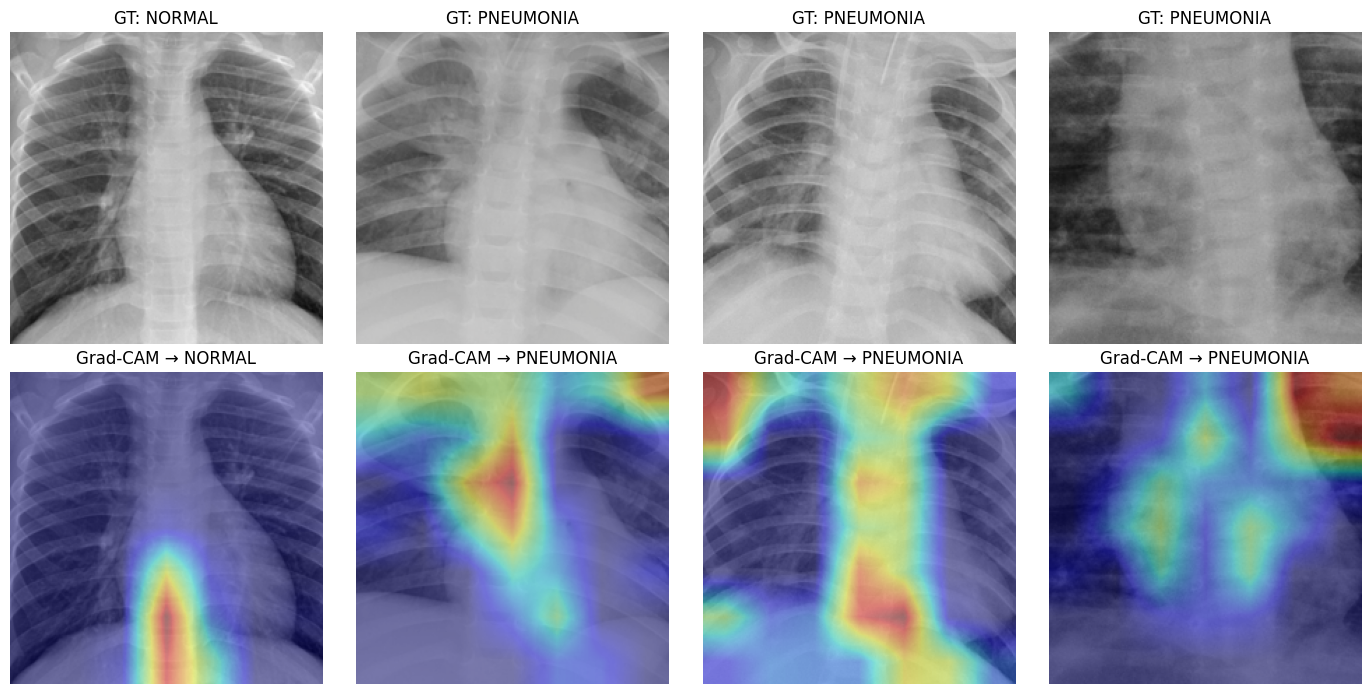

In [21]:
import torch.nn.functional as F

mean = torch.tensor(processor.image_mean).view(3, 1, 1)
std  = torch.tensor(processor.image_std).view(3, 1, 1)

def gradcam(pil_img):
    m = trainer.model.eval()
    x = processor(pil_img.convert("RGB"), return_tensors="pt")["pixel_values"].to(m.device)
    out = m(pixel_values=x, output_hidden_states=True)
    feat = out.hidden_states[-1]                    # 마지막 stage 특징맵 (1, C, 7, 7)
    cls = out.logits.argmax(-1).item()
    grad = torch.autograd.grad(out.logits[0, cls], feat)[0]
    w = grad.mean(dim=(2, 3), keepdim=True)         # 채널별 중요도
    cam = F.relu((w * feat).sum(1, keepdim=True)).float()
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    img = (x[0].float().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()   # 모델이 실제로 본 224×224 입력
    return img, cam.detach().cpu().numpy(), m.config.id2label[cls]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for col, ex in enumerate(raw_test.shuffle(seed=1).select(range(4))):
    img, cam, pred = gradcam(ex[IMAGE_COL])
    axes[0, col].imshow(img); axes[0, col].set_title(f"GT: {labels[ex[LABEL_COL]]}"); axes[0, col].axis("off")
    axes[1, col].imshow(img); axes[1, col].imshow(cam, cmap="jet", alpha=0.4)
    axes[1, col].set_title(f"Grad-CAM → {pred}"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()


**Grad-CAM 해석 포인트**
- 폐렴 예측 시 히트맵이 **폐야(lung field)의 음영 증가 부위(consolidation)** 에 모이면 → 임상적으로 타당한 근거
- 쇄골 위·이미지 모서리·'L/R' 마커 등에 모이면 → **shortcut learning** 의심 (데이터 편향)


---
## 7. 정리

| 단계 | 코드 |
|---|---|
| ① 모델 찾기 | huggingface.co/models 에서 task 필터 |
| ② 불러오기 | `pipeline(task=..., model=CHECKPOINT)` |
| ③ 데이터 적용 | `load_dataset(DATASET)` + stratified split |
| ④ 추론 | `pipeline(image)` |
| ⑤ 전이학습 | `AutoModelForImageClassification.from_pretrained(..., num_labels=2)` + `Trainer` |
| ⑥ 평가·해석 | Accuracy/F1/민감도/특이도, Confusion Matrix, Grad-CAM |
